# CCI multi-layer perceptron regression

Three independently tuned `MLPRegressor` pipelines forecast CCI at D+1, D+2, and D+3. Selection uses chronological validation data only; the test split remains unseen.

In [1]:
from __future__ import annotations

import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


def project_root() -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "pyproject.toml").exists():
            return candidate
    raise FileNotFoundError("Run this notebook from the experiments repository.")


PROJECT_ROOT = project_root()
DATA_DIR = PROJECT_ROOT / "data" / "processed" / "comfort_climate"
MODEL_DIR = PROJECT_ROOT / "models" / "comfort_climate" / "experiments"
FIGURE_DIR = PROJECT_ROOT / "reports" / "figures" / "comfort_climate"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
EXPERIMENT = "cci_mlp"
HORIZONS = (1, 2, 3)
RANDOM_STATE = 25945320
PARAMETERS = [
    {"hidden_layer_sizes": (32,), "alpha": 0.001, "learning_rate_init": 0.001},
    {"hidden_layer_sizes": (64, 32), "alpha": 0.001, "learning_rate_init": 0.001},
    {"hidden_layer_sizes": (64, 32), "alpha": 0.01, "learning_rate_init": 0.0005},
]

In [2]:
metadata = json.loads((DATA_DIR / "cci_feature_metadata.json").read_text())
FEATURE_COLUMNS = metadata["feature_columns"]
train = pd.read_csv(DATA_DIR / "sydney_cci_train.csv", parse_dates=["feature_date"]).set_index("feature_date")
validation = pd.read_csv(DATA_DIR / "sydney_cci_val.csv", parse_dates=["feature_date"]).set_index("feature_date")
assert train.index.max() < validation.index.min()
X_train, X_validation = train[FEATURE_COLUMNS], validation[FEATURE_COLUMNS]


def metrics(actual: pd.Series, predicted: np.ndarray) -> dict[str, float]:
    return {
        "mae": float(mean_absolute_error(actual, predicted)),
        "rmse": float(mean_squared_error(actual, predicted) ** 0.5),
        "r2": float(r2_score(actual, predicted)),
        "pred_std": float(np.std(predicted)),
    }


TARGET_COLUMNS = metadata["target_columns"]
FEATURE_GROUPS = metadata["feature_groups"]


def climatology_profile(frame: pd.DataFrame, target: str, window: int = 15) -> pd.Series:
    """Return a year-wrapped, smoothed day-of-year CCI profile from training data only."""
    profile = frame.groupby(frame.index.dayofyear)[target].mean().reindex(range(1, 367))
    half_window = window // 2
    wrapped = pd.concat([profile.iloc[-half_window:], profile, profile.iloc[:half_window]])
    return wrapped.rolling(window, center=True, min_periods=1).mean().iloc[half_window:-half_window]


CLIMATOLOGY = {target: climatology_profile(train, target) for target in TARGET_COLUMNS}
validation_climatology = {
    target: validation.index.dayofyear.map(CLIMATOLOGY[target]).to_numpy()
    for target in TARGET_COLUMNS
}
print(f"Training rows: {len(train):,}; validation rows: {len(validation):,}; features: {len(FEATURE_COLUMNS)}")

Training rows: 2,889; validation rows: 363; features: 86


In [3]:
base_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("mlp", MLPRegressor(
        max_iter=500,
        early_stopping=True,
        validation_fraction=0.15,
        n_iter_no_change=25,
        random_state=RANDOM_STATE,
    )),
])

models, predictions, selected_params, rows = {}, {}, {}, []
for horizon in HORIZONS:
    target = f"cci_t{horizon}"
    y_train, y_validation = train[target], validation[target]
    candidates = {}
    for params in PARAMETERS:
        candidate = clone(base_pipeline).set_params(**{f"mlp__{key}": value for key, value in params.items()})
        candidates[tuple(params.items())] = candidate.fit(X_train, y_train)
    best_key = min(candidates, key=lambda key: mean_absolute_error(y_validation, candidates[key].predict(X_validation)))
    model = candidates[best_key]
    prediction = model.predict(X_validation)
    models[horizon], predictions[horizon] = model, prediction
    selected_params[horizon] = dict(best_key)
    rows.extend([
        {"horizon": horizon, "model": "MLP", **metrics(y_validation, prediction)},
        {"horizon": horizon, "model": "Persistence", **metrics(y_validation, validation["cci"].to_numpy())},
        {"horizon": horizon, "model": "Climatology", **metrics(y_validation, validation_climatology[target])},
    ])

results = pd.DataFrame(rows).set_index(["horizon", "model"])
print(selected_params)
results

/Users/juanvargas/UTS/3rd Semester/AdvanceML/Assignment_2/36120-26SP-AT2-25945320-experiments/.venv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/juanvargas/UTS/3rd Semester/AdvanceML/Assignment_2/36120-26SP-AT2-25945320-experiments/.venv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/juanvargas/UTS/3rd Semester/AdvanceML/Assignment_2/36120-26SP-AT2-25945320-experiments/.venv/lib/python3.14/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


{1: {'hidden_layer_sizes': (32,), 'alpha': 0.001, 'learning_rate_init': 0.001}, 2: {'hidden_layer_sizes': (32,), 'alpha': 0.001, 'learning_rate_init': 0.001}, 3: {'hidden_layer_sizes': (32,), 'alpha': 0.001, 'learning_rate_init': 0.001}}


mae       rmse        r2   pred_std
horizon model                                                
1       MLP          8.041865  10.628188  0.066604   8.868231
        Persistence  7.561764   9.928426  0.185468  10.936744
        Climatology  8.047145  10.486969  0.091244   4.778343
2       MLP          8.846802  11.760191 -0.140040   8.416570
        Persistence  8.624439  11.520842 -0.094107  10.936744
        Climatology  7.964432  10.460972  0.097940   4.778343
3       MLP          9.053911  11.769563 -0.140103   8.444724
        Persistence  9.161983  12.014701 -0.188090  10.936744
        Climatology  8.052734  10.558250  0.082498   4.778343

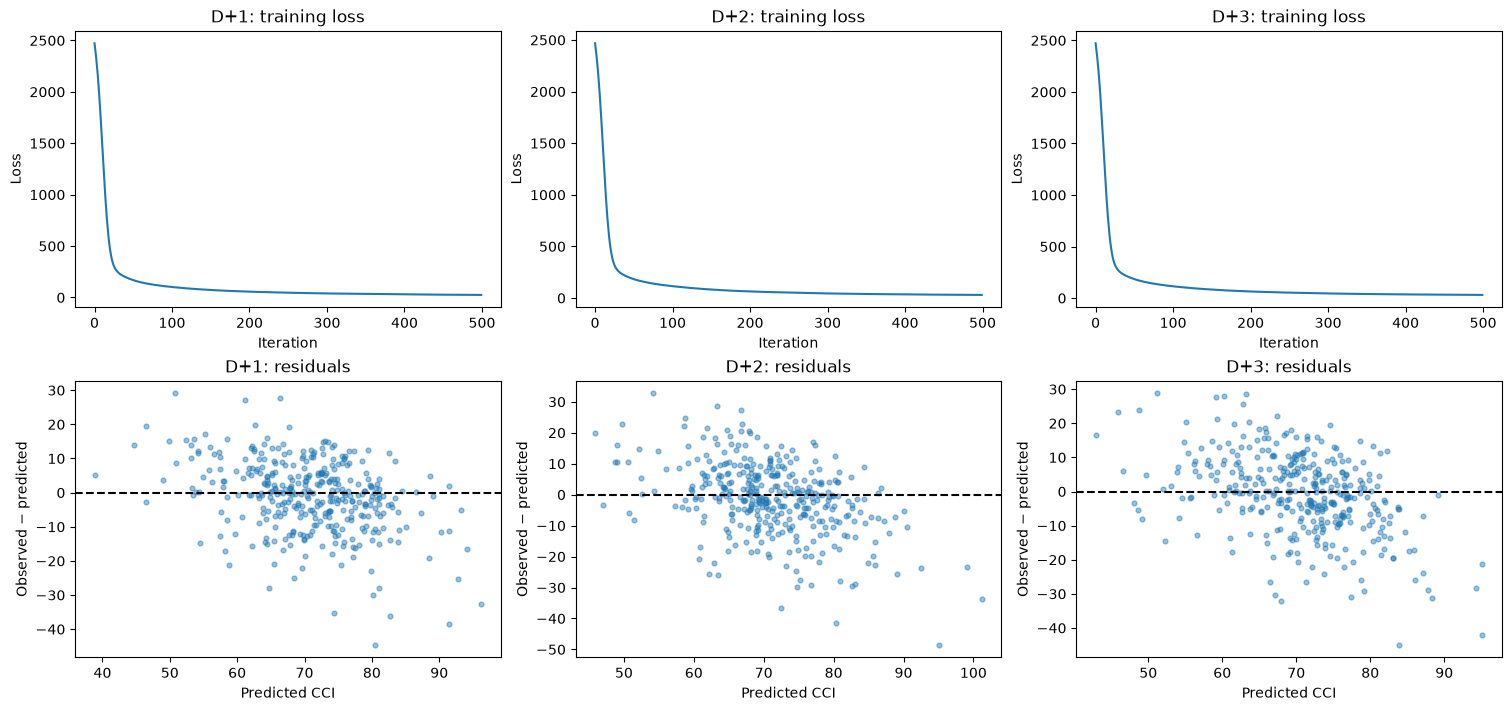

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7), constrained_layout=True)
for column, horizon in enumerate(HORIZONS):
    observed, predicted = validation[f"cci_t{horizon}"], predictions[horizon]
    axes[0, column].plot(models[horizon].named_steps["mlp"].loss_curve_)
    axes[0, column].set(title=f"D+{horizon}: training loss", xlabel="Iteration", ylabel="Loss")
    axes[1, column].scatter(predicted, observed - predicted, alpha=0.45, s=12)
    axes[1, column].axhline(0, color="black", linestyle="--")
    axes[1, column].set(title=f"D+{horizon}: residuals", xlabel="Predicted CCI", ylabel="Observed − predicted")
fig.savefig(FIGURE_DIR / f"{EXPERIMENT}-diagnostics.png", dpi=150)
plt.show()

In [5]:
sys.path.insert(0, str(PROJECT_ROOT / "36120_26sp_at2_25945320_experiments"))
from modeling.deployment import export_tabular_bundle

experiment_metadata = {
    "experiment": EXPERIMENT,
    "student_id": "25945320",
    "algorithm": "Multi-layer Perceptron Regressor",
    "prediction_type": "regression",
    "feature_columns": FEATURE_COLUMNS,
    "feature_column_order_is_significant": True,
    "selected_hyperparameters": selected_params,
    "validation_metrics": {f"cci_t{h}": results.loc[(h, "MLP")].to_dict() for h in HORIZONS},
    "baseline_metrics": {f"cci_t{h}": {b: results.loc[(h, b)].to_dict() for b in ("Persistence", "Climatology")} for h in HORIZONS},
    "split_boundaries": metadata["split_boundaries"],
    "embargo_days": metadata["embargo_days"],
    "evaluated_on": ["train", "val"],
    "held_out": ["test"],
}
bundle_dir = export_tabular_bundle(
    output_dir=MODEL_DIR / EXPERIMENT,
    experiment=EXPERIMENT,
    models=models,
    feature_columns=FEATURE_COLUMNS,
    metadata=experiment_metadata,
    model_family="mlp",
)
print(f"Saved API-compatible bundle to {bundle_dir.relative_to(PROJECT_ROOT)}")

Saved API-compatible bundle to models/comfort_climate/experiments/cci_mlp


## 4. Feature-group ablation

Each cumulative feature family is scored on the chronological validation split. This identifies whether added engineered features improve generalisation beyond same-day CCI persistence.

In [ ]:
GROUP_ORDER = [
    "same_day_observations", "same_day_scores", "lags", "rolling_statistics",
    "rolling_precipitation", "rolling_gusts", "deltas", "seasonal",
]
FEATURE_GROUPS = metadata["feature_groups"]
ordered_groups = [group for group in GROUP_ORDER if group in FEATURE_GROUPS]
ordered_groups += [group for group in FEATURE_GROUPS if group not in ordered_groups]

ablation_configs = {"persistence only": ["cci"]}
cumulative = []
for group in ordered_groups:
    cumulative = list(dict.fromkeys([*cumulative, *FEATURE_GROUPS[group]]))
    ablation_configs[group] = cumulative

ablation_rows = []
for label, columns in ablation_configs.items():
    for horizon in HORIZONS:
        target = f"cci_t{horizon}"
        candidate = clone(models[horizon]).fit(train[columns], train[target])
        ablation_rows.append({
            "config": label,
            "target": target,
            "mae": mean_absolute_error(validation[target], candidate.predict(validation[columns])),
        })

ablation = pd.DataFrame(ablation_rows)
ablation_mae = ablation.pivot(index="config", columns="target", values="mae").reindex(ablation_configs)
ablation_mae.insert(0, "n_features", [len(columns) for columns in ablation_configs.values()])
print("Validation MAE by cumulative feature set (lower is better):\n")
print(ablation_mae.to_string())

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), constrained_layout=True)
ablation_mae[[f"cci_t{h}" for h in HORIZONS]].plot(marker="o", ax=axes[0])
for horizon, style in zip(HORIZONS, ("--", "-.", ":")):
    axes[0].axhline(
        results.loc[(horizon, "Persistence"), "mae"], color=f"C{horizon - 1}", linestyle=style, alpha=0.55
    )
axes[0].set(title="Validation MAE as families are added", ylabel="MAE (CCI)", xlabel="")
(-ablation_mae[[f"cci_t{h}" for h in HORIZONS]].diff()).plot.bar(ax=axes[1])
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set(title="MAE reduction contributed by each family", ylabel="MAE reduction", xlabel="")
fig.savefig(FIGURE_DIR / f"{EXPERIMENT}-ablation.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Validation predictions and feature attribution

Predictions are plotted against the held-out validation period. Permutation importance measures the validation-MAE penalty caused by shuffling each feature; it is a model-agnostic attribution, not a causal claim.

In [ ]:
from sklearn.inspection import permutation_importance

fig, axes = plt.subplots(2, len(HORIZONS), figsize=(15, 7), constrained_layout=True)
for column, horizon in enumerate(HORIZONS):
    target = f"cci_t{horizon}"
    observed = validation[target]
    predicted = predictions[horizon]
    axes[0, column].scatter(observed, predicted, alpha=0.45, s=12)
    axes[0, column].plot([0, 100], [0, 100], "k--")
    axes[0, column].set(title=f"D+{horizon}: observed vs predicted", xlabel="Observed CCI", ylabel="Predicted CCI")
    axes[1, column].plot(validation.index, observed, label="observed", linewidth=1.4)
    axes[1, column].plot(validation.index, predicted, label="MLP prediction", linewidth=1.1)
    axes[1, column].set(title=f"{target} over validation", xlabel="Feature date", ylabel="CCI")
    axes[1, column].legend(fontsize=8)
fig.suptitle("MLP: validation predictions by horizon", fontsize=12)
fig.savefig(FIGURE_DIR / f"{EXPERIMENT}-validation.png", dpi=150, bbox_inches="tight")
plt.show()

permutation = {}
for horizon in HORIZONS:
    target = f"cci_t{horizon}"
    importance = permutation_importance(
        models[horizon], X_validation, validation[target], scoring="neg_mean_absolute_error",
        n_repeats=10, random_state=RANDOM_STATE, n_jobs=1,
    )
    permutation[f"cci_t{horizon}"] = importance.importances_mean

importances = pd.DataFrame(permutation, index=FEATURE_COLUMNS)
importances["mean"] = importances.mean(axis=1)
feature_family = {column: group for group, columns in FEATURE_GROUPS.items() for column in columns}
importances["family"] = [feature_family[column] for column in importances.index]
top = importances.sort_values("mean", ascending=False).head(20)
family_totals = importances.groupby("family")[[f"cci_t{h}" for h in HORIZONS]].sum()

fig, axes = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)
top["mean"].sort_values().plot.barh(ax=axes[0])
axes[0].set(title="Top 20 features by mean permutation importance", xlabel="Validation MAE increase")
family_totals.plot.bar(ax=axes[1])
axes[1].set(title="Permutation importance by family and horizon", ylabel="Summed MAE increase", xlabel="")
fig.savefig(FIGURE_DIR / f"{EXPERIMENT}-importance.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Generalisation check and artefact export

The train-versus-validation comparison makes any optimism gap visible. The exported metadata records the selected settings, metrics, feature families, and validation attribution used for model selection.

In [ ]:
generalisation_rows = []
for horizon in HORIZONS:
    target = f"cci_t{horizon}"
    generalisation_rows.extend([
        {"target": target, "split": "train", "mae": mean_absolute_error(train[target], models[horizon].predict(X_train))},
        {"target": target, "split": "validation", "mae": mean_absolute_error(validation[target], predictions[horizon])},
    ])
generalisation = pd.DataFrame(generalisation_rows)
print(generalisation.pivot(index="target", columns="split", values="mae"))

ax = generalisation.pivot(index="target", columns="split", values="mae").plot.bar(figsize=(8, 4.5))
ax.set(title="MLP train versus validation MAE", ylabel="MAE (CCI)", xlabel="Forecast target")
ax.figure.tight_layout()
ax.figure.savefig(FIGURE_DIR / f"{EXPERIMENT}-generalisation.png", dpi=150, bbox_inches="tight")
plt.show()

sys.path.insert(0, str(PROJECT_ROOT / "36120_26sp_at2_25945320_experiments"))
from modeling.deployment import export_tabular_bundle

experiment_metadata = {
    "experiment": EXPERIMENT,
    "student_id": "25945320",
    "algorithm": "Multi-layer Perceptron Regression",
    "prediction_type": "regression",
    "feature_columns": FEATURE_COLUMNS,
    "feature_column_order_is_significant": True,
    "feature_groups": FEATURE_GROUPS,
    "selected_hyperparameters": selected_params,
    "validation_metrics": {f"cci_t{h}": results.loc[(h, "MLP")].to_dict() for h in HORIZONS},
    "baseline_metrics": {f"cci_t{h}": {baseline: results.loc[(h, baseline)].to_dict() for baseline in ("Persistence", "Climatology")} for h in HORIZONS},
    "feature_importance": {target: importances[target].sort_values(ascending=False).head(20).to_dict() for target in [f"cci_t{h}" for h in HORIZONS]},
    "importance_method": "validation permutation importance; MAE increase after feature shuffling",
    "generalisation_mae": generalisation.pivot(index="target", columns="split", values="mae").to_dict(),
    "split_boundaries": metadata["split_boundaries"],
    "embargo_days": metadata["embargo_days"],
    "evaluated_on": ["train", "val"],
    "held_out": ["test"],
}
bundle_dir = export_tabular_bundle(
    output_dir=MODEL_DIR / EXPERIMENT,
    experiment=EXPERIMENT,
    models=models,
    feature_columns=FEATURE_COLUMNS,
    metadata=experiment_metadata,
    model_family="mlp",
)
print(f"Saved API-compatible bundle to {bundle_dir.relative_to(PROJECT_ROOT)}")